# Assignment 8: Noise Models

**Objective:** Generate five kinds of noise - Uniform, Gaussian, Erlang, Exponential and Rayleigh - in two ways each: (a) derived manually from uniform random numbers using the inverse-transform method, and (b) using NumPy's built-in distributions. Compare their histograms and add them to an image.

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_image(size=128, seed=42):
    """Build a grayscale test image (gradient + shapes + texture) with NumPy and OpenCV."""
    rng = np.random.default_rng(seed)

    # Smooth horizontal gradient as the background
    canvas = np.tile(np.linspace(40, 140, size, dtype=np.float32), (size, 1))

    # Bright square, dark circle and a mid-grey diagonal line give us edges and flat regions
    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), 220, -1)
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, 30, -1)
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), 180, 3)

    # Light texture so the image is not perfectly smooth
    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

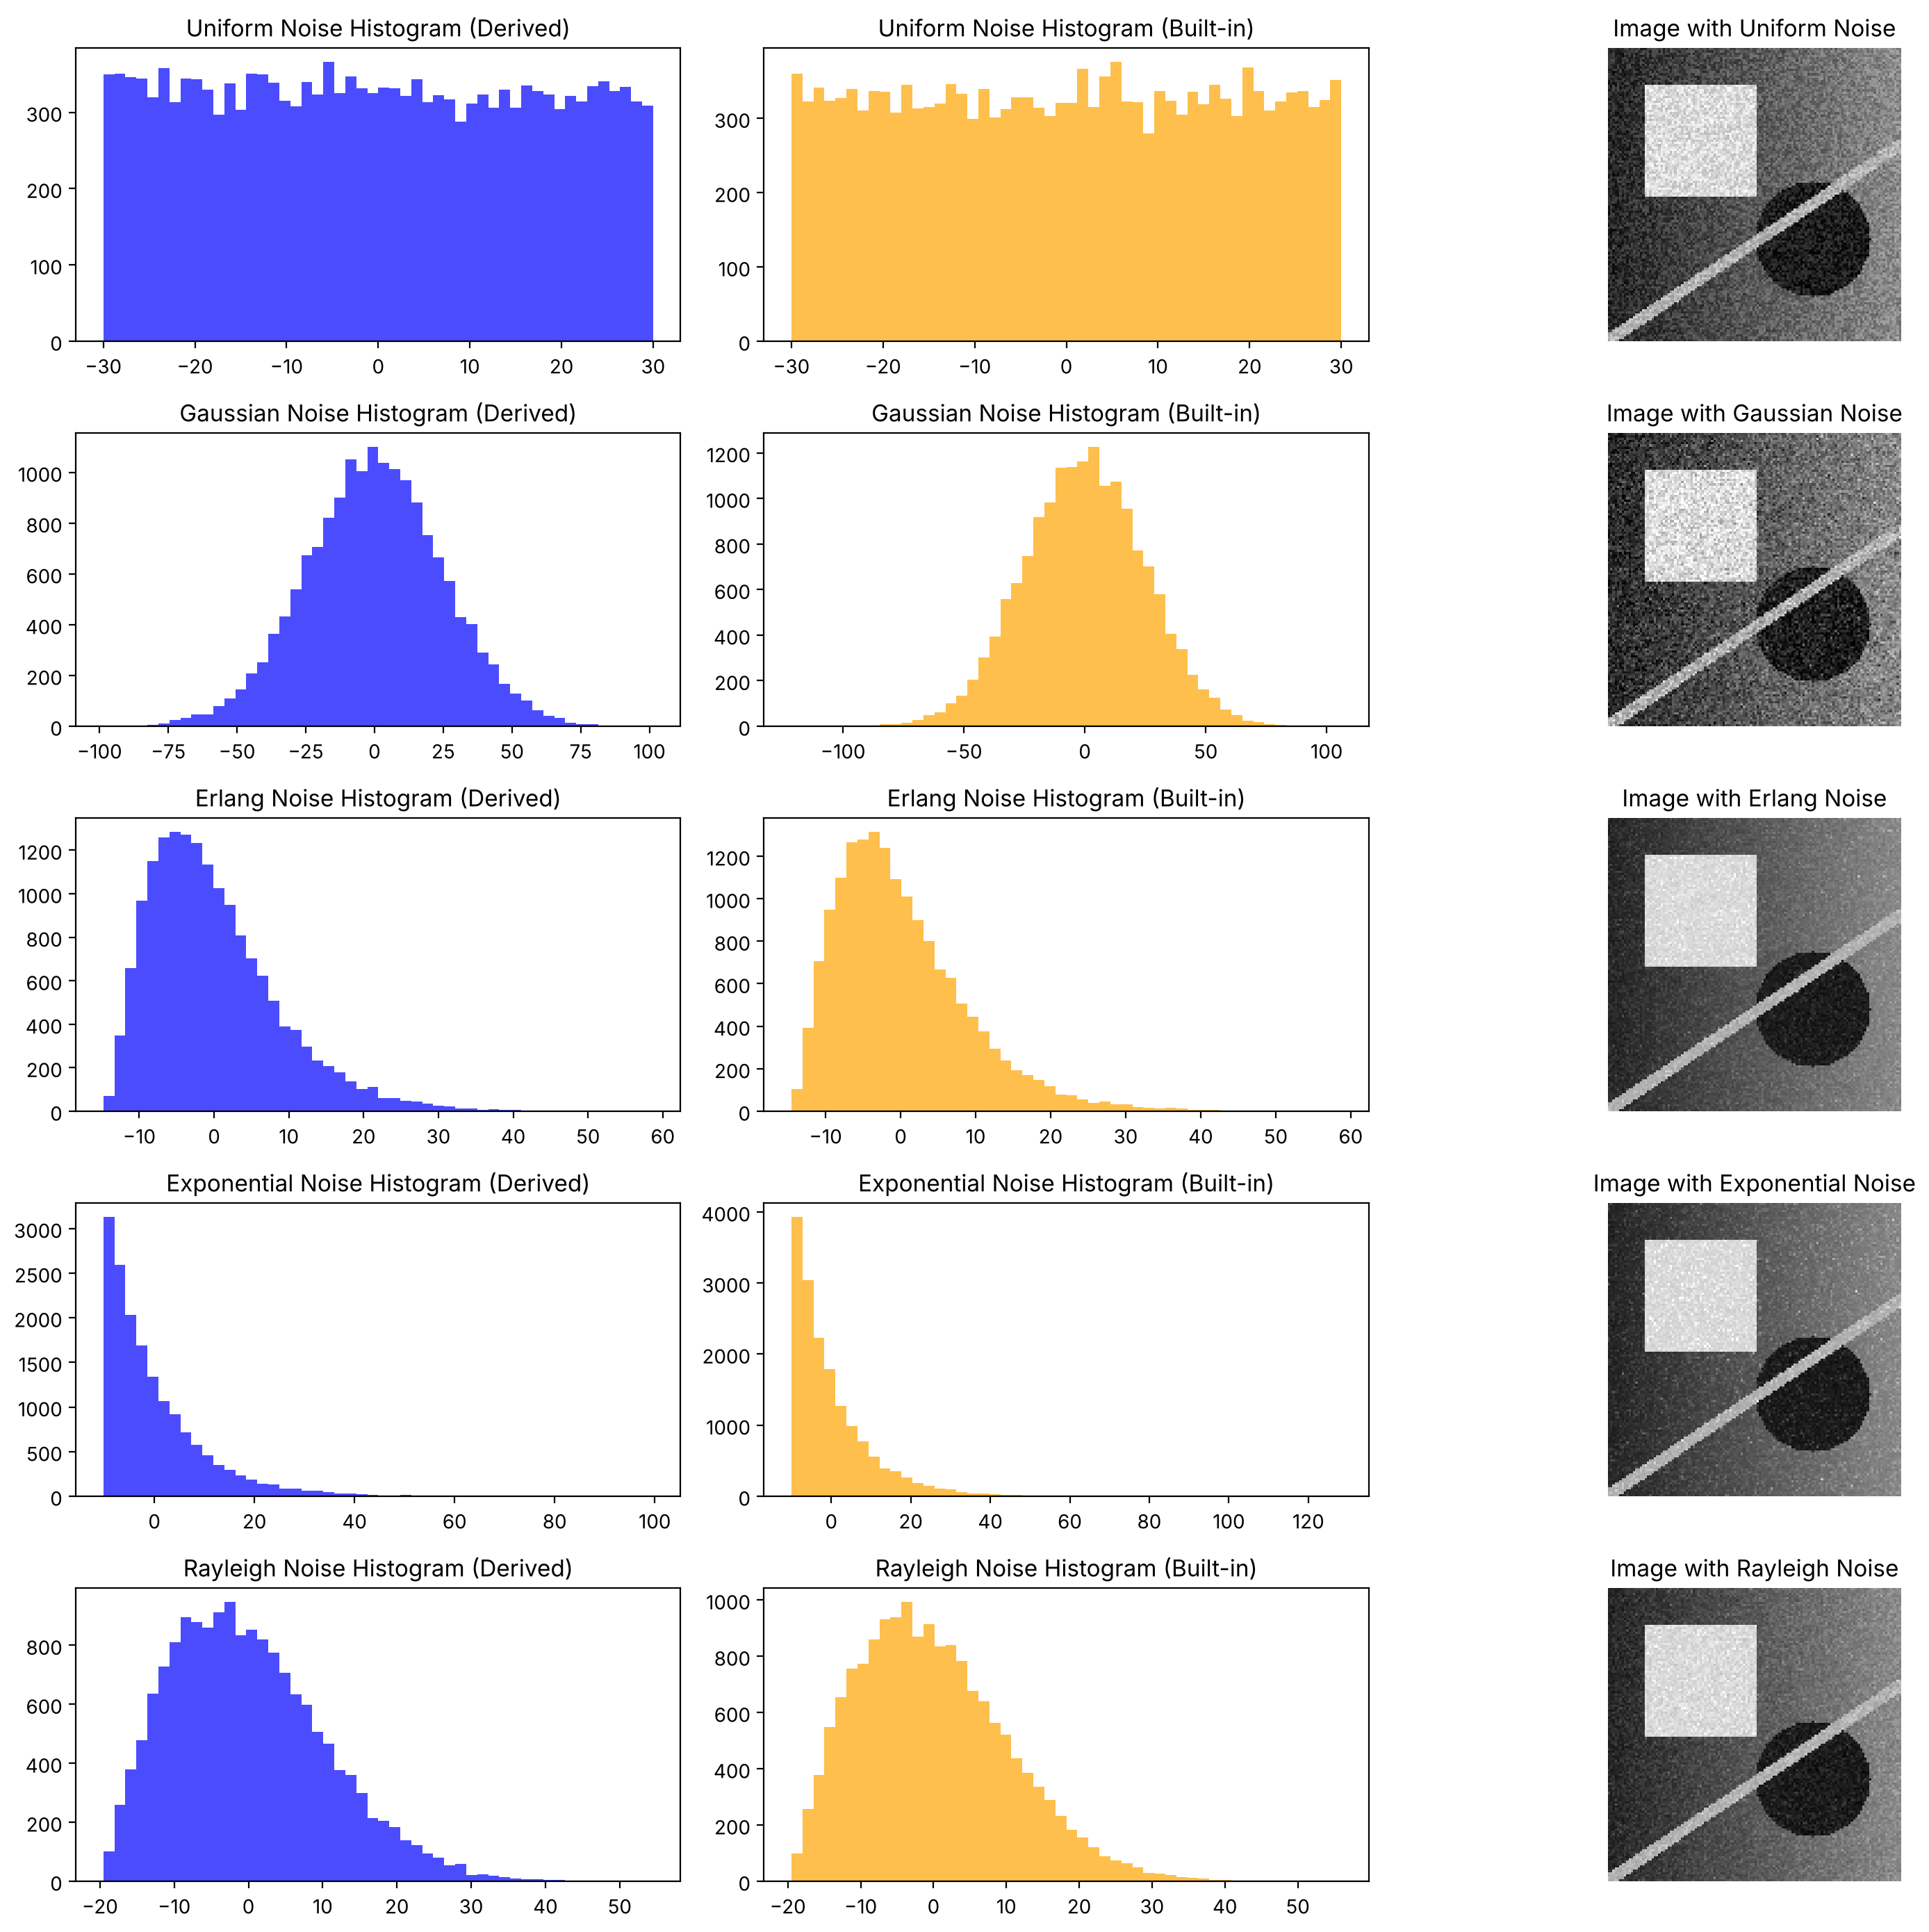

In [2]:
np.random.seed(0)   # reproducible noise

grayscale_image = create_demo_image()
height, width = grayscale_image.shape

# --- Uniform noise in [low, high] ------------------------------------------
low, high = -30, 30
uniform_derived = low + (high - low) * np.random.rand(height, width)
uniform_builtin = np.random.uniform(low, high, (height, width))

# --- Gaussian noise (Box-Muller transform), mean 0, std 25 -----------------
random_a = np.random.rand(height, width)
random_b = np.random.rand(height, width)
gaussian_derived = 25 * np.sqrt(-2 * np.log(random_a + 1e-7)) * np.cos(2 * np.pi * random_b)
gaussian_builtin = np.random.normal(0, 25, (height, width))

# --- Erlang noise (sum of k exponentials), zero-centred --------------------
erlang_k, erlang_rate = 3, 0.2
random_product = np.ones((height, width))
for _ in range(erlang_k):
    random_product *= np.random.rand(height, width) + 1e-7
erlang_derived = -(1 / erlang_rate) * np.log(random_product)
erlang_derived -= np.mean(erlang_derived)
erlang_builtin = np.random.gamma(erlang_k, 1 / erlang_rate, (height, width)) - (erlang_k / erlang_rate)

# --- Exponential noise, zero-centred ---------------------------------------
exponential_rate = 0.1
exponential_derived = -(1 / exponential_rate) * np.log(1 - np.random.rand(height, width) + 1e-7)
exponential_derived -= np.mean(exponential_derived)
exponential_builtin = np.random.exponential(1 / exponential_rate, (height, width)) - (1 / exponential_rate)

# --- Rayleigh noise, zero-centred ------------------------------------------
rayleigh_b = 500
rayleigh_derived = np.sqrt(-rayleigh_b * np.log(1 - np.random.rand(height, width) + 1e-7))
rayleigh_derived -= np.mean(rayleigh_derived)
rayleigh_builtin = np.random.rayleigh(np.sqrt(rayleigh_b / 2), (height, width))
rayleigh_builtin -= np.mean(rayleigh_builtin)

noise_models = [
    ("Uniform", uniform_derived, uniform_builtin),
    ("Gaussian", gaussian_derived, gaussian_builtin),
    ("Erlang", erlang_derived, erlang_builtin),
    ("Exponential", exponential_derived, exponential_builtin),
    ("Rayleigh", rayleigh_derived, rayleigh_builtin),
]

plt.figure(figsize=(15, 14))
for index, (name, derived_noise, builtin_noise) in enumerate(noise_models):
    noisy_image = np.clip(grayscale_image + derived_noise, 0, 255).astype(np.uint8)

    plt.subplot(5, 3, 3 * index + 1)
    plt.hist(derived_noise.ravel(), bins=50, color="blue", alpha=0.7)
    plt.title(f"{name} Noise Histogram (Derived)")

    plt.subplot(5, 3, 3 * index + 2)
    plt.hist(builtin_noise.ravel(), bins=50, color="orange", alpha=0.7)
    plt.title(f"{name} Noise Histogram (Built-in)")

    plt.subplot(5, 3, 3 * index + 3)
    plt.imshow(noisy_image, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Image with {name} Noise")
    plt.axis("off")

plt.tight_layout()
plt.show()